<a href="https://colab.research.google.com/github/Fannno/GenAI-Practice/blob/main/week02/mnist_mlp_gradio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 雙隱藏層 MNIST 手寫數字辨識

## 本次修改重點
本次以老師的 MNIST 範例為基礎，將原本三個隱藏層、
每層 20 個神經元，改成兩個隱藏層，分別設定為 128、64 個神經元。

隱藏層使用 ReLU，輸出層保留 10 個神經元與 Softmax，
對應數字 0～9。

訓練方式保留 MSE、SGD 與學習率 0.087，
設定訓練 10 輪、批次大小 32。
另外保留 10% 資料作為驗證集，記錄每輪結果與最高驗證正確率，
最後使用 Gradio 測試手寫數字。

## AI 使用說明
本次使用生成式 AI 協助建議兩個隱藏層的神經元數量、
提供模型修改範例，以及協助整理驗證結果的統計程式與說明文字。

我參考建議採用 128、64 的設定，並了解到最後的 10 個神經元
屬於輸出層，不算隱藏層。神經元數量增加不代表辨識一定更準確，
仍須透過實際訓練結果判斷。

以下附上相關提問與回答截圖。

## 1. 讀入套件

In [ ]:
!pip install gradio

In [ ]:
%matplotlib inline

# 標準數據分析、畫圖套件
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

# 神經網路方面
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD

# 互動設計用
from ipywidgets import interact_manual

# 神速打造 web app 的 Gradio
import gradio as gr

## 2. 讀入 MNIST 數據庫
MNIST 包含數字 0～9 的手寫圖片，每張圖片大小為 28×28。
先載入 60,000 筆訓練資料與 10,000 筆測試資料，再確認資料筆數。

> MNIST 是由 LeCun 等人修改自 NIST 的手寫數字圖庫原始網頁。是深度學習最著名的範例。

In [ ]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [ ]:
print(f'訓練資料總筆數為 {len(x_train)} 筆資料')
print(f'測試資料總筆數為 {len(x_test)} 筆資料')

訓練資料總筆數為 60000 筆資料
測試資料總筆數為 10000 筆資料


### 2.1 圖片前處理

將每張 28×28 的圖片攤平成 784 個數值，作為全連結神經網路的輸入。
像素值除以 255，將數值範圍縮放至 0～1。

In [ ]:
x_train = x_train.reshape(60000, 784)/255
x_test = x_test.reshape(10000, 784)/255

### 2.2 答案前處理

將數字答案轉成長度為 10 的獨熱編碼：
正確類別的位置為 1，其餘位置為 0，對應模型的 10 個輸出。

In [ ]:
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

## 3. 建立雙隱藏層模型

模型架構為 784 → 128 → 64 → 10。

兩個隱藏層分別有 128、64 個神經元，使用 ReLU。
輸出層有 10 個神經元，使用 Softmax 產生數字 0～9 的預測分數。
這個模型共有兩個隱藏層，最後一層是輸出層。

In [ ]:
model = Sequential()

第一個隱藏層設定為 128 個神經元，使用 ReLU。
每張圖片原本是 28×28，攤平後有 784 個數值，
所以這裡將輸入數量設為 784。

In [ ]:
model.add(Dense(128, input_dim=784, activation="relu"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


第二個隱藏層設定為 64 個神經元，同樣使用 ReLU，
繼續組合前一層學到的特徵。這層會接收上一層的輸出，
因此不用再指定輸入數量。

In [ ]:
model.add(Dense(64, activation="relu"))

最後是輸出層，因為要辨識數字 0～9，所以設定 10 個神經元。
使用 Softmax，讓這 10 個類別的預測分數加總為 1，
並以分數最高的類別作為模型的辨識結果。
這一層是輸出層，不算在兩個隱藏層裡。

In [ ]:
model.add(Dense(10, activation='softmax'))

### 3.1 設定訓練方式

保留老師範例的 MSE 損失函數與 SGD 最佳化方法，
學習率設為 0.087，並使用 accuracy 記錄正確率。

In [ ]:
model.compile(loss='mse', optimizer=SGD(learning_rate=0.087), metrics=['accuracy'])

## 4. 確認模型架構

使用 model.summary() 確認兩個隱藏層分別有 128、64 個神經元，
輸出層有 10 個神經元，並查看模型參數量。

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## 5. 訓練與驗證

訓練設定為 20 輪，批次大小為 32。
從 60,000 筆資料保留 10% 作為驗證集，
因此實際用於訓練的是 54,000 筆，驗證資料為 6,000 筆。

驗證資料不參與權重更新，用來觀察模型對未參與訓練資料的辨識表現。

In [ ]:
history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.6600 - loss: 0.0528 - val_accuracy: 0.8905 - val_loss: 0.0210
Epoch 2/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8797 - loss: 0.0199 - val_accuracy: 0.9168 - val_loss: 0.0134
Epoch 3/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9014 - loss: 0.0157 - val_accuracy: 0.9248 - val_loss: 0.0116
Epoch 4/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9117 - loss: 0.0139 - val_accuracy: 0.9330 - val_loss: 0.0106
Epoch 5/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9199 - loss: 0.0128 - val_accuracy: 0.9362 - val_loss: 0.0098
Epoch 6/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9248 - loss: 0.0119 - val_accuracy: 0.9400 - val_loss: 0.0093
Epoch 7/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9297 - loss: 0.0112 - val_accuracy: 0.9455 - val_loss: 0.0087
Epoch 8/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9335 - loss: 0.0106 - 

In [ ]:
best_epoch = int(np.argmax(history.history['val_accuracy'])) + 1
best_val_accuracy = max(history.history['val_accuracy'])

print("模型：784 → 128 → 64 → 10")
print("隱藏層：2 層；神經元數量：128、64")
print("激發函數：隱藏層 ReLU；輸出層 Softmax")
print("損失函數：MSE；最佳化方法：SGD")
print("學習率：0.087")
print("訓練輪數：20；批次大小：32；驗證比例：10%")
print(f"最高驗證正確率：{best_val_accuracy:.2%}")
print(f"出現在第 {best_epoch} 輪")

模型：784 → 128 → 64 → 10
隱藏層：2 層；神經元數量：128、64
激發函數：隱藏層 ReLU；輸出層 Softmax
損失函數：MSE；最佳化方法：SGD
學習率：0.087
訓練輪數：20；批次大小：32；驗證比例：10%
最高驗證正確率：96.72%
出現在第 20 輪


## 6. 檢查訓練結果

比較每輪的訓練正確率與驗證正確率，觀察模型表現的變化。
另外使用測試集評估訓練完成後的模型。

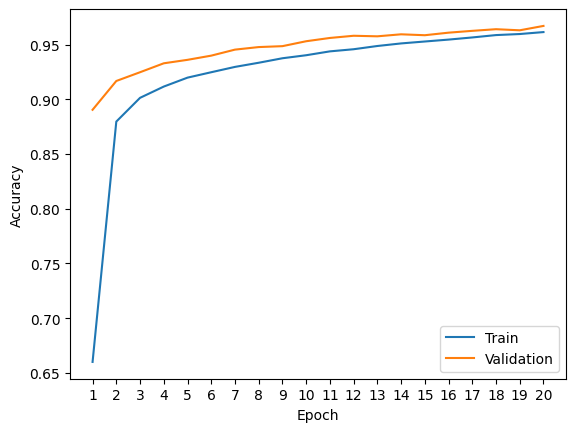

In [ ]:
epochs = range(1, len(history.history['accuracy']) + 1)

plt.plot(epochs, history.history['accuracy'], label='Train')
plt.plot(epochs, history.history['val_accuracy'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.xticks(epochs)
plt.legend()
plt.show()

In [ ]:
loss, acc = model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9565 - loss: 0.0068


In [ ]:
print(f"測試資料正確率 {acc*100:.2f}%")

測試資料正確率 95.65%


對測試圖片進行預測，取分數最高的類別作為辨識結果。

In [ ]:
predict = np.argmax(model.predict(x_test), axis=-1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


`x_test` 每筆資料已經換成 784 維的向量, 要整型回 28x28 的矩陣才能當成圖形顯示出來。

In [ ]:
def test(測試編號):
    plt.imshow(x_test[測試編號].reshape(28,28), cmap='Greys')
    print('神經網路判斷為:', predict[測試編號])

In [ ]:
interact_manual(test, 測試編號=(0, 9999));

interactive(children=(IntSlider(value=4999, description='測試編號', max=9999), Button(description='Run Interact', …

## 7. Gradio 手寫測試

在畫板上手寫一個數字，送出後查看模型預測的前三個類別。
畫面上的百分比是這張圖片的類別預測分數，
不等於整批驗證資料的正確率。

此處使用完成第 10 輪訓練後的模型；
前面統計的最高驗證正確率，可能出現在較早的輪次。

In [ ]:
def resize_image(inp):
    # 圖在 inp["layers"][0]
    image = np.array(inp["layers"][0], dtype=np.float32)
    image = image.astype(np.uint8)

    # 轉成 PIL 格式
    image_pil = Image.fromarray(image)

    # Alpha 通道設為白色, 再把圖從 RGBA 轉成 RGB
    background = Image.new("RGB", image_pil.size, (255, 255, 255))
    background.paste(image_pil, mask=image_pil.split()[3]) # 把圖片粘貼到白色背景上，使用透明通道作為遮罩
    image_pil = background

    # 轉換為灰階圖像
    image_gray = image_pil.convert("L")

    # 將灰階圖像縮放到 28x28, 轉回 numpy array
    img_array = np.array(image_gray.resize((28, 28), resample=Image.LANCZOS))

    # 配合 MNIST 數據集
    img_array = 255 - img_array

    # 拉平並縮放
    img_array = img_array.reshape(1, 784) / 255.0

    return img_array

In [ ]:
def recognize_digit(inp):
    img_array = resize_image(inp)
    prediction = model.predict(img_array).flatten()
    labels = list('0123456789')
    return {labels[i]: float(prediction[i]) for i in range(10)}

In [ ]:
iface = gr.Interface(
    fn=recognize_digit,
    inputs=gr.Sketchpad(),
    outputs=gr.Label(num_top_classes=3),
    title="雙隱藏層手寫數字辨識",
    description="請寫一個 0～9 的數字，按下 Submit 查看辨識結果。"
)

iface.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://7f5fcdb0ec7245b68f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 286ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://7f5fcdb0ec7245b68f.gradio.live
